# Data processing

In [3]:
import pandas as pd

DROP = [
    "rxn_id",
    "ligand_1_cas",
    "ligand_1_smiles",
    "product_1_product_2_ddg_kcal",
]

literature = pd.read_csv("../../../data/HF-Literature.tsv", sep="\t")
literature["ligand_catalyst_ratio"] = literature["ligand_1_eq"] / literature["catalyst_1_eq"]

X_lit, y_lit, labels = (
    literature.drop(columns=DROP, axis=1),
    literature["product_1_product_2_ddg_kcal"],
    literature["ligand_1_cas"],
)

experimental = pd.read_csv("../../../data/HF-Experimental.tsv", sep="\t")
experimental["ligand_catalyst_ratio"] = experimental["ligand_1_eq"] / experimental["catalyst_1_eq"]

In [2]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut

run = False

if run:
    logo = LeaveOneGroupOut()

    split = 0
    # First split to separate train+val from test
    for train_val_idx, test_idx in logo.split(X_lit, y_lit, labels):
        # Second split to separate train from val
        val_logo = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
        train_idx, val_idx = next(
            val_logo.split(
                np.array(train_val_idx).reshape(-1, 1),
                groups=labels.iloc[train_val_idx],
            )
        )

        # Save the splits
        train_subset = literature.iloc[train_val_idx].iloc[train_idx].copy()
        train_subset["split"] = "train"

        val_subset = literature.iloc[train_val_idx].iloc[val_idx].copy()
        val_subset["split"] = "val"

        test_subset = literature.iloc[test_idx].copy()
        test_subset["split"] = "test"

        combined = pd.concat([train_subset, val_subset, test_subset])
        combined[["ligand_1_smiles", "product_1_product_2_ddg_kcal", "split"]].to_csv(
            f"data/splits-csv/combined-{split}.csv", index=False
        )

        # Save the reaction conditions
        reaction_conditions = combined[
            [
                "temperature_deg_c",
                "ligand_catalyst_ratio",
                "reagent_1_pressure_bar",
                "reagent_2_pressure_bar",
            ]
        ].to_numpy()

        np.savez(f"data/splits-npz/reaction_conditions-{split}.npz", reaction_conditions)

        split += 1

    experimental[["ligand_1_smiles", "product_1_product_2_ddg_kcal"]].to_csv(
        "data/experimental/data/experimental.csv", index=False
    )
    exp_reaction_conditions = experimental[
        [
            "temperature_deg_c",
            "ligand_catalyst_ratio",
            "reagent_1_pressure_bar",
            "reagent_2_pressure_bar",
        ]
    ].to_numpy()

    np.savez("data/experimental/data/reaction_conditions.npz", exp_reaction_conditions)

# Results analysis

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

lit_ddg = []
test_preds = []
for split in range(156):
    try:
        split_df = pd.read_csv(f"data/splits-csv/combined-{split}.csv")
        pred_df = pd.read_csv(f"results/split_{split}/preds.csv")

        assert len(split_df) == len(pred_df), f"Split {split} has different lengths"

        split_df["predictions_ddG"] = pred_df["product_1_product_2_ddg_kcal"]

        train = split_df[split_df["split"] == "train"]
        val = split_df[split_df["split"] == "val"]
        test = split_df[split_df["split"] == "test"]

        lit_ddg.extend(test["product_1_product_2_ddg_kcal"].to_list())
        test_preds.extend(test["predictions_ddG"].to_list())
    except FileNotFoundError:
        print(f"Split {split} not found, skipping.")
        continue

loco_rmse = root_mean_squared_error(lit_ddg, test_preds)
loco_mae = mean_absolute_error(lit_ddg, test_preds)
loco_r2 = r2_score(lit_ddg, test_preds)

experimental = pd.read_csv("data/experimental/data/experimental.csv")

experimental_pred = pd.read_csv("data/experimental/results/preds.csv")

exp_rmse = root_mean_squared_error(
    experimental["product_1_product_2_ddg_kcal"],
    experimental_pred["product_1_product_2_ddg_kcal"],
)
exp_r2 = r2_score(
    experimental["product_1_product_2_ddg_kcal"],
    experimental_pred["product_1_product_2_ddg_kcal"],
)

print(f"LOCO RMSE: {loco_rmse:.3f}, MAE: {loco_mae:.3f}, R2: {loco_r2:.3f}")
print(f"Experimental RMSE: {exp_rmse:.3f}, R2: {exp_r2:.3f}")

Text(-1.7, 5.7, 'Lit. RMSE = 1.00\nLit. $R^2$ = 0.38\nExp. RMSE = 1.03\nExp. $R^2$ = -0.13')

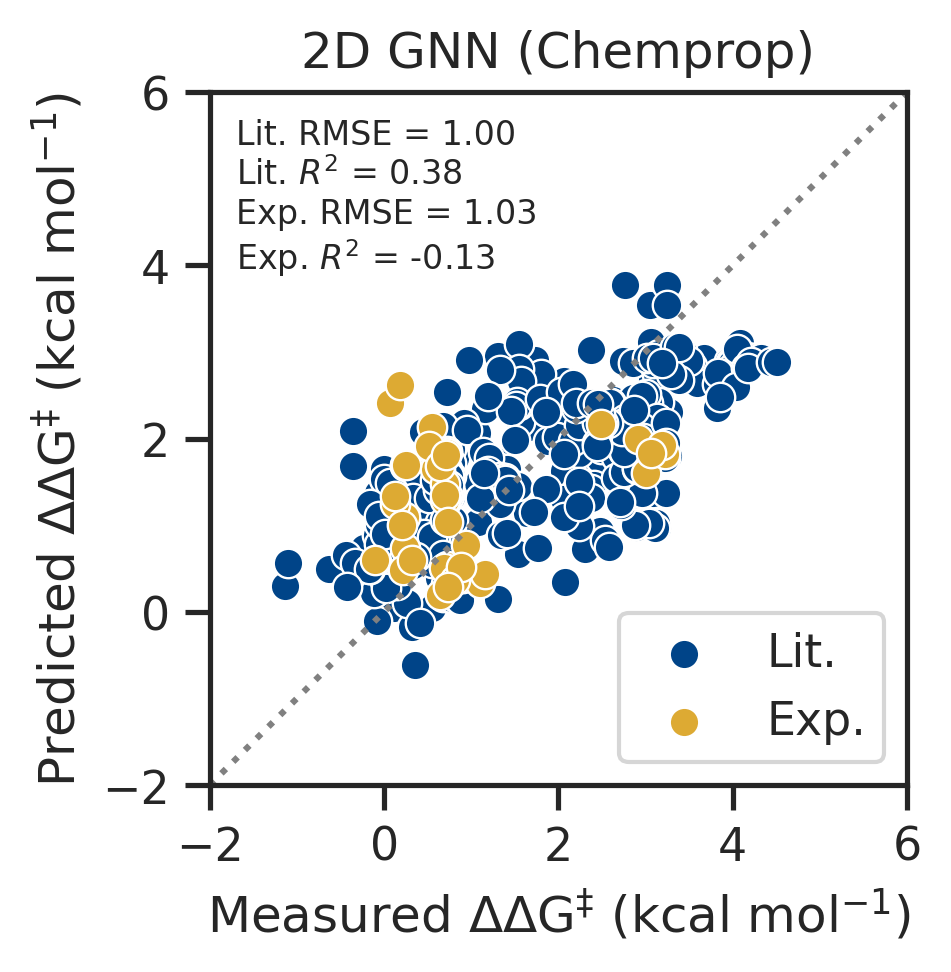

In [5]:
# Define colors and theme
colors = ["#004488", "#DDAA33", "#BB5566", "#000000"]
color = sns.color_palette(colors)
plt.rcParams.update({"figure.figsize": (3, 3)})
sns.set(rc={"figure.dpi": 300})
sns.set_theme(style="ticks", palette=color)
plt.tight_layout()

ax = sns.scatterplot(
    x=lit_ddg,
    y=test_preds,
    alpha=1,
    s=50,
    legend=True,
    label="Lit.",
)

sns.scatterplot(
    x=experimental["product_1_product_2_ddg_kcal"],
    y=experimental_pred["product_1_product_2_ddg_kcal"],
    alpha=1,
    s=50,
    legend=True,
    label="Exp.",
)

ax.set(
    xlabel=r"Measured $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
    ylabel=r"Predicted $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
)
ax.set_xlim(-2, 6)
ax.set_ylim(-2, 6)

ax.plot(
    [0, 1],
    [0, 1],
    ":",
    color="grey",
    transform=ax.transAxes,
)
ax.set_title("2D GNN (Chemprop)")

ax.text(
    -1.7,
    5.7,
    f"Lit. RMSE = {loco_rmse:0.2f}\nLit. $R^2$ = {loco_r2:0.2f}\n"
    f"Exp. RMSE = {exp_rmse:0.2f}\nExp. $R^2$ = {exp_r2:0.2f}",
    fontsize=8,
    horizontalalignment="left",
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.9),
)
